# Test Duck

Use this notebook to chart the saved crop-sequence benchmark and check that Duck’s live API responds. Run it beside `Train Duck Crop Sequence.ipynb` in Jupyter, or in the local OperationDucks folder. The Arduino screenshots use different models and tests.

In [1]:
from pathlib import Path
import json

report_dir = Path(".duck-model/rotation")
reports = sorted(report_dir.glob("*.json"), key=lambda path: path.stat().st_mtime, reverse=True)
if not reports:
    raise FileNotFoundError("Run Train Duck Crop Sequence.ipynb first to create a benchmark report.")
report = json.loads(reports[0].read_text(encoding="utf-8"))
print(f"{reports[0].name} · {report['device']} · {report['test_examples']} test fields · {report['test_counties']} held-out counties")

9ff188a769b7c352.json · cpu · 126 test fields · 4 held-out counties


## Graph the crop benchmark

Accuracy is the share of fields with the correct crop class. Macro recall weights each observed class equally. These results are retrospective. This checkpoint report contains final metrics, so it has no epoch-by-epoch loss series.

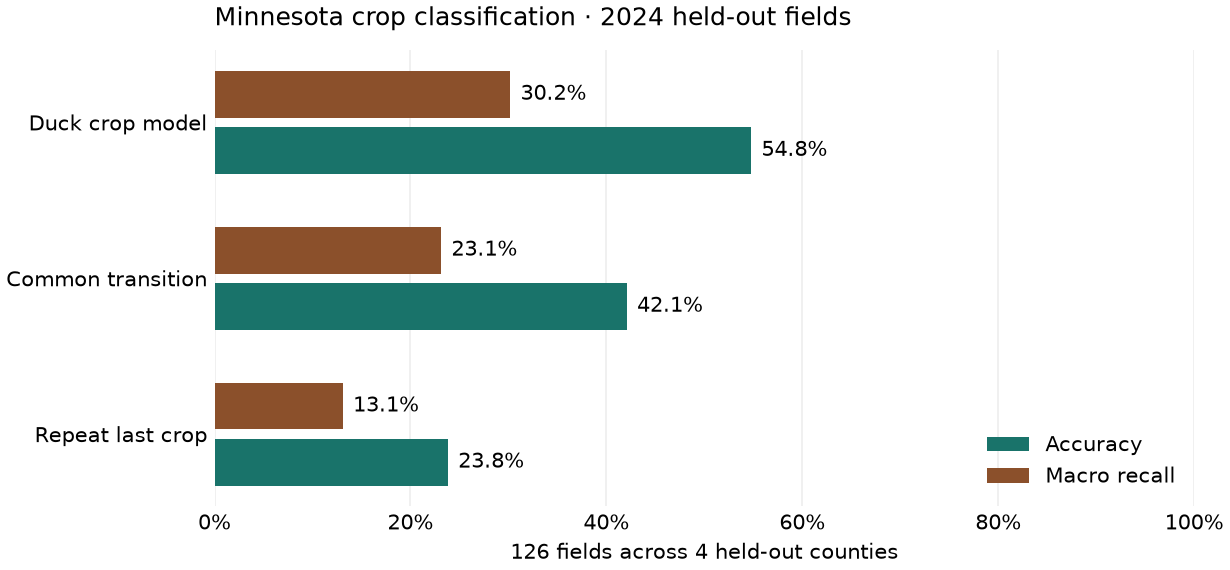

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

methods = [("last_crop", "Repeat last crop"), ("most_common_transition", "Common transition"), ("model", "Duck crop model")]
fig, ax = plt.subplots(figsize=(8.2, 3.8), layout="constrained")
positions = list(range(len(methods)))
for offset, metric, name, color in [
    (-0.18, "accuracy", "Accuracy", "#19736a"),
    (0.18, "macro_recall", "Macro recall", "#8b502b"),
]:
    scores = [report["metrics"][method][metric] for method, _ in methods]
    bars = ax.barh([y + offset for y in positions], scores, height=0.30, label=name, color=color)
    ax.bar_label(bars, labels=[f"{score:.1%}" for score in scores], padding=5)
ax.set_yticks(positions, [label for _, label in methods])
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis="both", length=0)
ax.grid(axis="x", alpha=0.22)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.set_title(f"Minnesota crop classification · {report['test_year']} held-out fields", loc="left", pad=12)
ax.set_xlabel(f"{report['test_examples']} fields across {report['test_counties']} held-out counties")
ax.legend(frameon=False, loc="lower right")
plt.show()

## Test live chat

The test sends a sample question to Duck on localhost. The A30 VM can use the default /ask endpoint. On a dashboard-only machine, set api_url to http://127.0.0.1:3000/api/duck to test the dashboard and configured tunnel.

In [3]:
from urllib.request import Request, urlopen

api_url = "http://127.0.0.1:19230/ask"
body = json.dumps({"question": "Find SMAP soil moisture in 2025", "scope": "Worldwide"}).encode()
request = Request(api_url, data=body, headers={"Content-Type": "application/json"})
with urlopen(request, timeout=30) as response:
    assert response.status == 200
    reply = json.load(response)
assert "SPL4SMGP" in reply["answer"], "Expected a SMAP catalog record."
assert any(source["url"].startswith("https://cmr.earthdata.nasa.gov/") for source in reply["sources"])
print("PASS · Duck returned SMAP catalog records and a NASA source link.")
print(reply["answer"])

PASS · Duck returned SMAP catalog records and a NASA source link.
SMAP soil moisture for worldwide, 2025-01-01 to 2025-12-31. Latest catalog matches by observation start time.
SPL4SMGP: 2025-12-31T21:00:00.000Z · SMAP_L4_SM_gph_20251231T223000_Vv8013_001.h5_u9loH5HD; 2025-12-31T18:00:00.000Z · SMAP_L4_SM_gph_20251231T193000_Vv8013_001.h5_u9loH5HD; 2025-12-31T15:00:00.000Z · SMAP_L4_SM_gph_20251231T163000_Vv8013_001.h5_u9loH5HD
These are scene records. Pixel values and quality flags require reading the science assets.


## Test the dashboard

1. In Duck, set **Place** to `Worldwide` and ask `Find SMAP soil moisture in 2025`. Open a source link.
2. Search for `47.012545, -94.696672`, then open **Farm risks → Crop history**. Confirm the 2017–2024 classes. Clear Duck's **Place** field and ask `Show the CSB crop history` to check its field-specific answer.
3. On a reply, open **Give feedback**, select a rating, and submit only if you want that question and answer saved for review. Look for **Feedback saved for review**.
4. Use **Read aloud** after the voice worker and its reference recording are configured. Browser dictation can be checked independently using **Dictate question** and reviewing the resulting text before sending.